# MCM 처리 후 astrocyte ACHES와 SNAP-a 점수

**GSE228927**과 **GSE282665**의 astrocyte 표본을 비교한다. [다시 그리는 방법](README.md)

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

results_subdir = Path("data/perturbation_validation/results")
here = Path.cwd()
project = next(
    (path for path in (here, *here.parents) if (path / results_subdir / "program_scores.tsv").is_file()),
    None,
)
if project is None:
    raise FileNotFoundError("이 저장소의 루트 또는 notebooks/perturbation에서 실행하세요.")
results = project / results_subdir
figures = project / "figures"
figure_numbers = {"GSE228927": "24", "GSE282665": "25"}
selected_datasets = list(figure_numbers)

planned = pd.read_csv(results / "planned_sample_scores.tsv", sep="\t")
coverage = pd.read_csv(results / "program_coverage.tsv", sep="\t")
planned = planned.loc[planned["dataset"].isin(selected_datasets) & planned["recipient"].eq("astrocyte")]
coverage = coverage.loc[coverage["dataset"].isin(selected_datasets) & coverage["recipient"].eq("astrocyte")]

## 표본 점수와 비교 괄호

점은 개별 표본, 가로선은 조건 평균, 회색 선은 같은 human recipient line을 나타낸다. 각 괄호는 resting-MCM과 처리 조건을 잇고 양측 검정의 **BH-FDR 보정 q값**을 표시한다. `*`는 q < 0.05, `**`는 q < 0.01, `***`는 q < 0.001, `ns`는 q ≥ 0.05다.

- GSE228927은 조건 간 실험 매칭 정보가 없어 독립군을 가정한 Welch 검정을 적용했다. †는 낮은 mouse SNAP-a coverage를 나타낸다.
- GSE282665는 같은 recipient line 내 차이로 paired t 검정을 수행했다.

표에는 대비별 평균 차이와 95% 신뢰구간을 함께 제공한다.

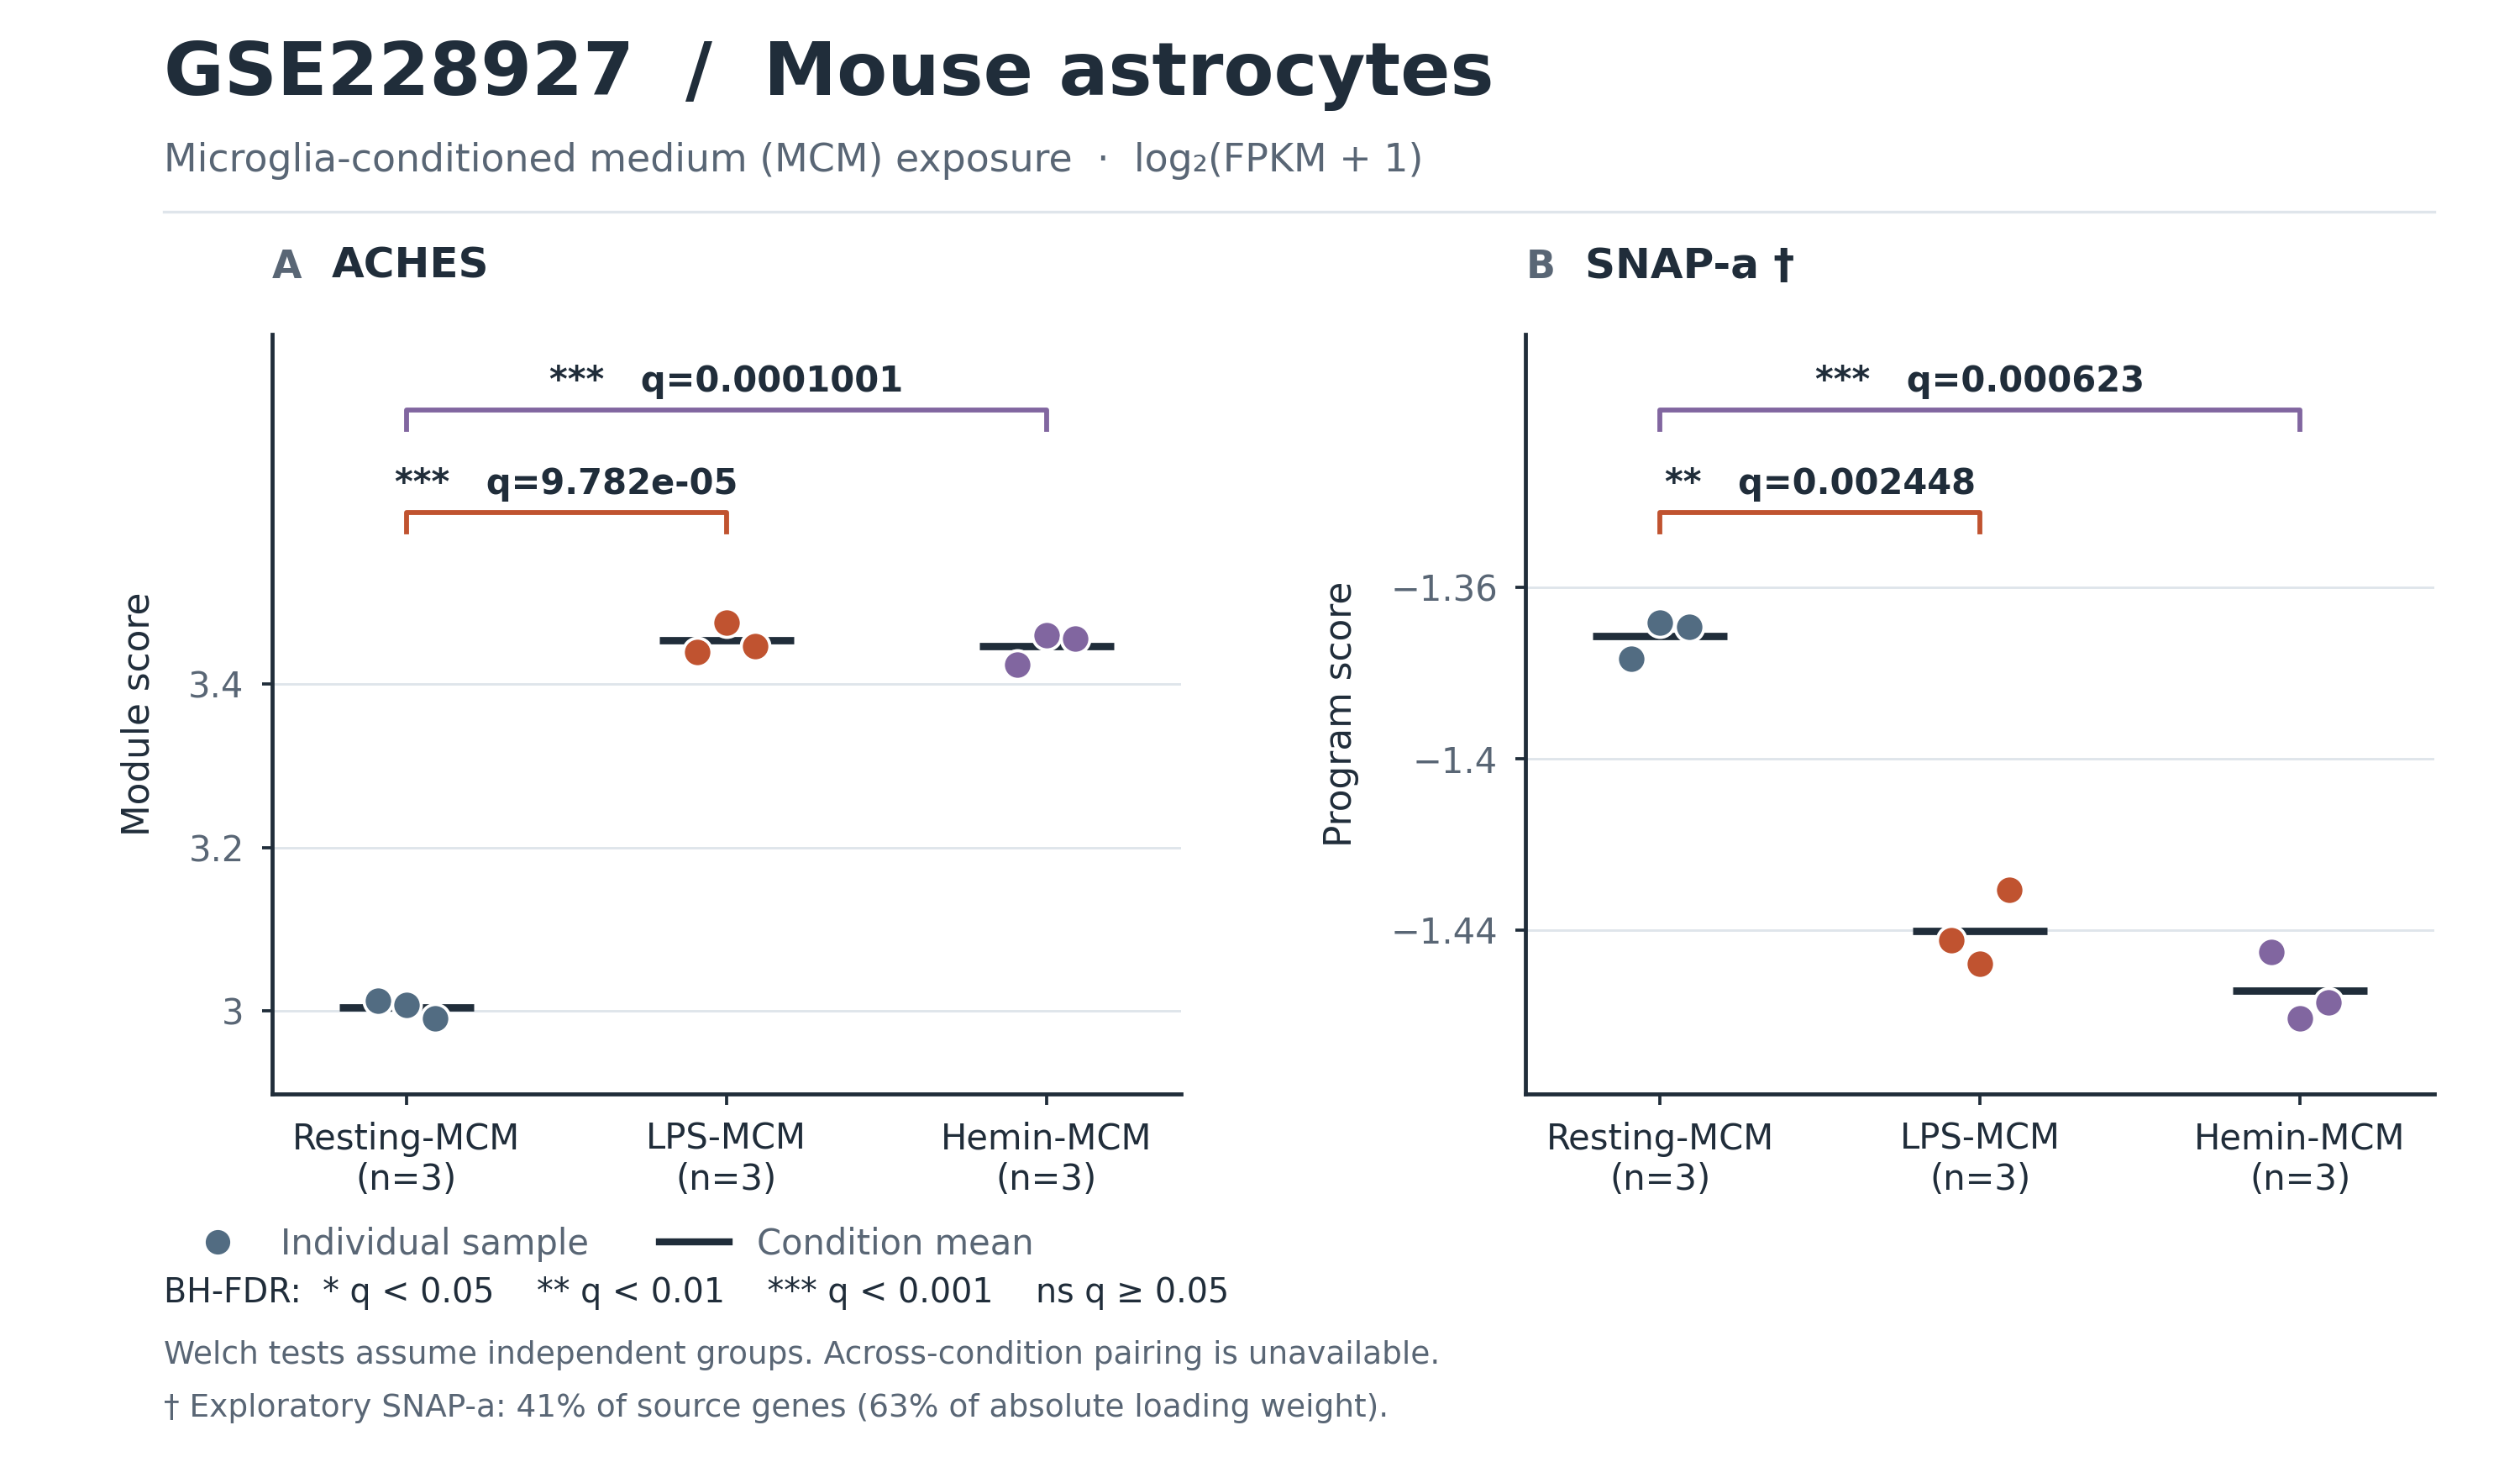

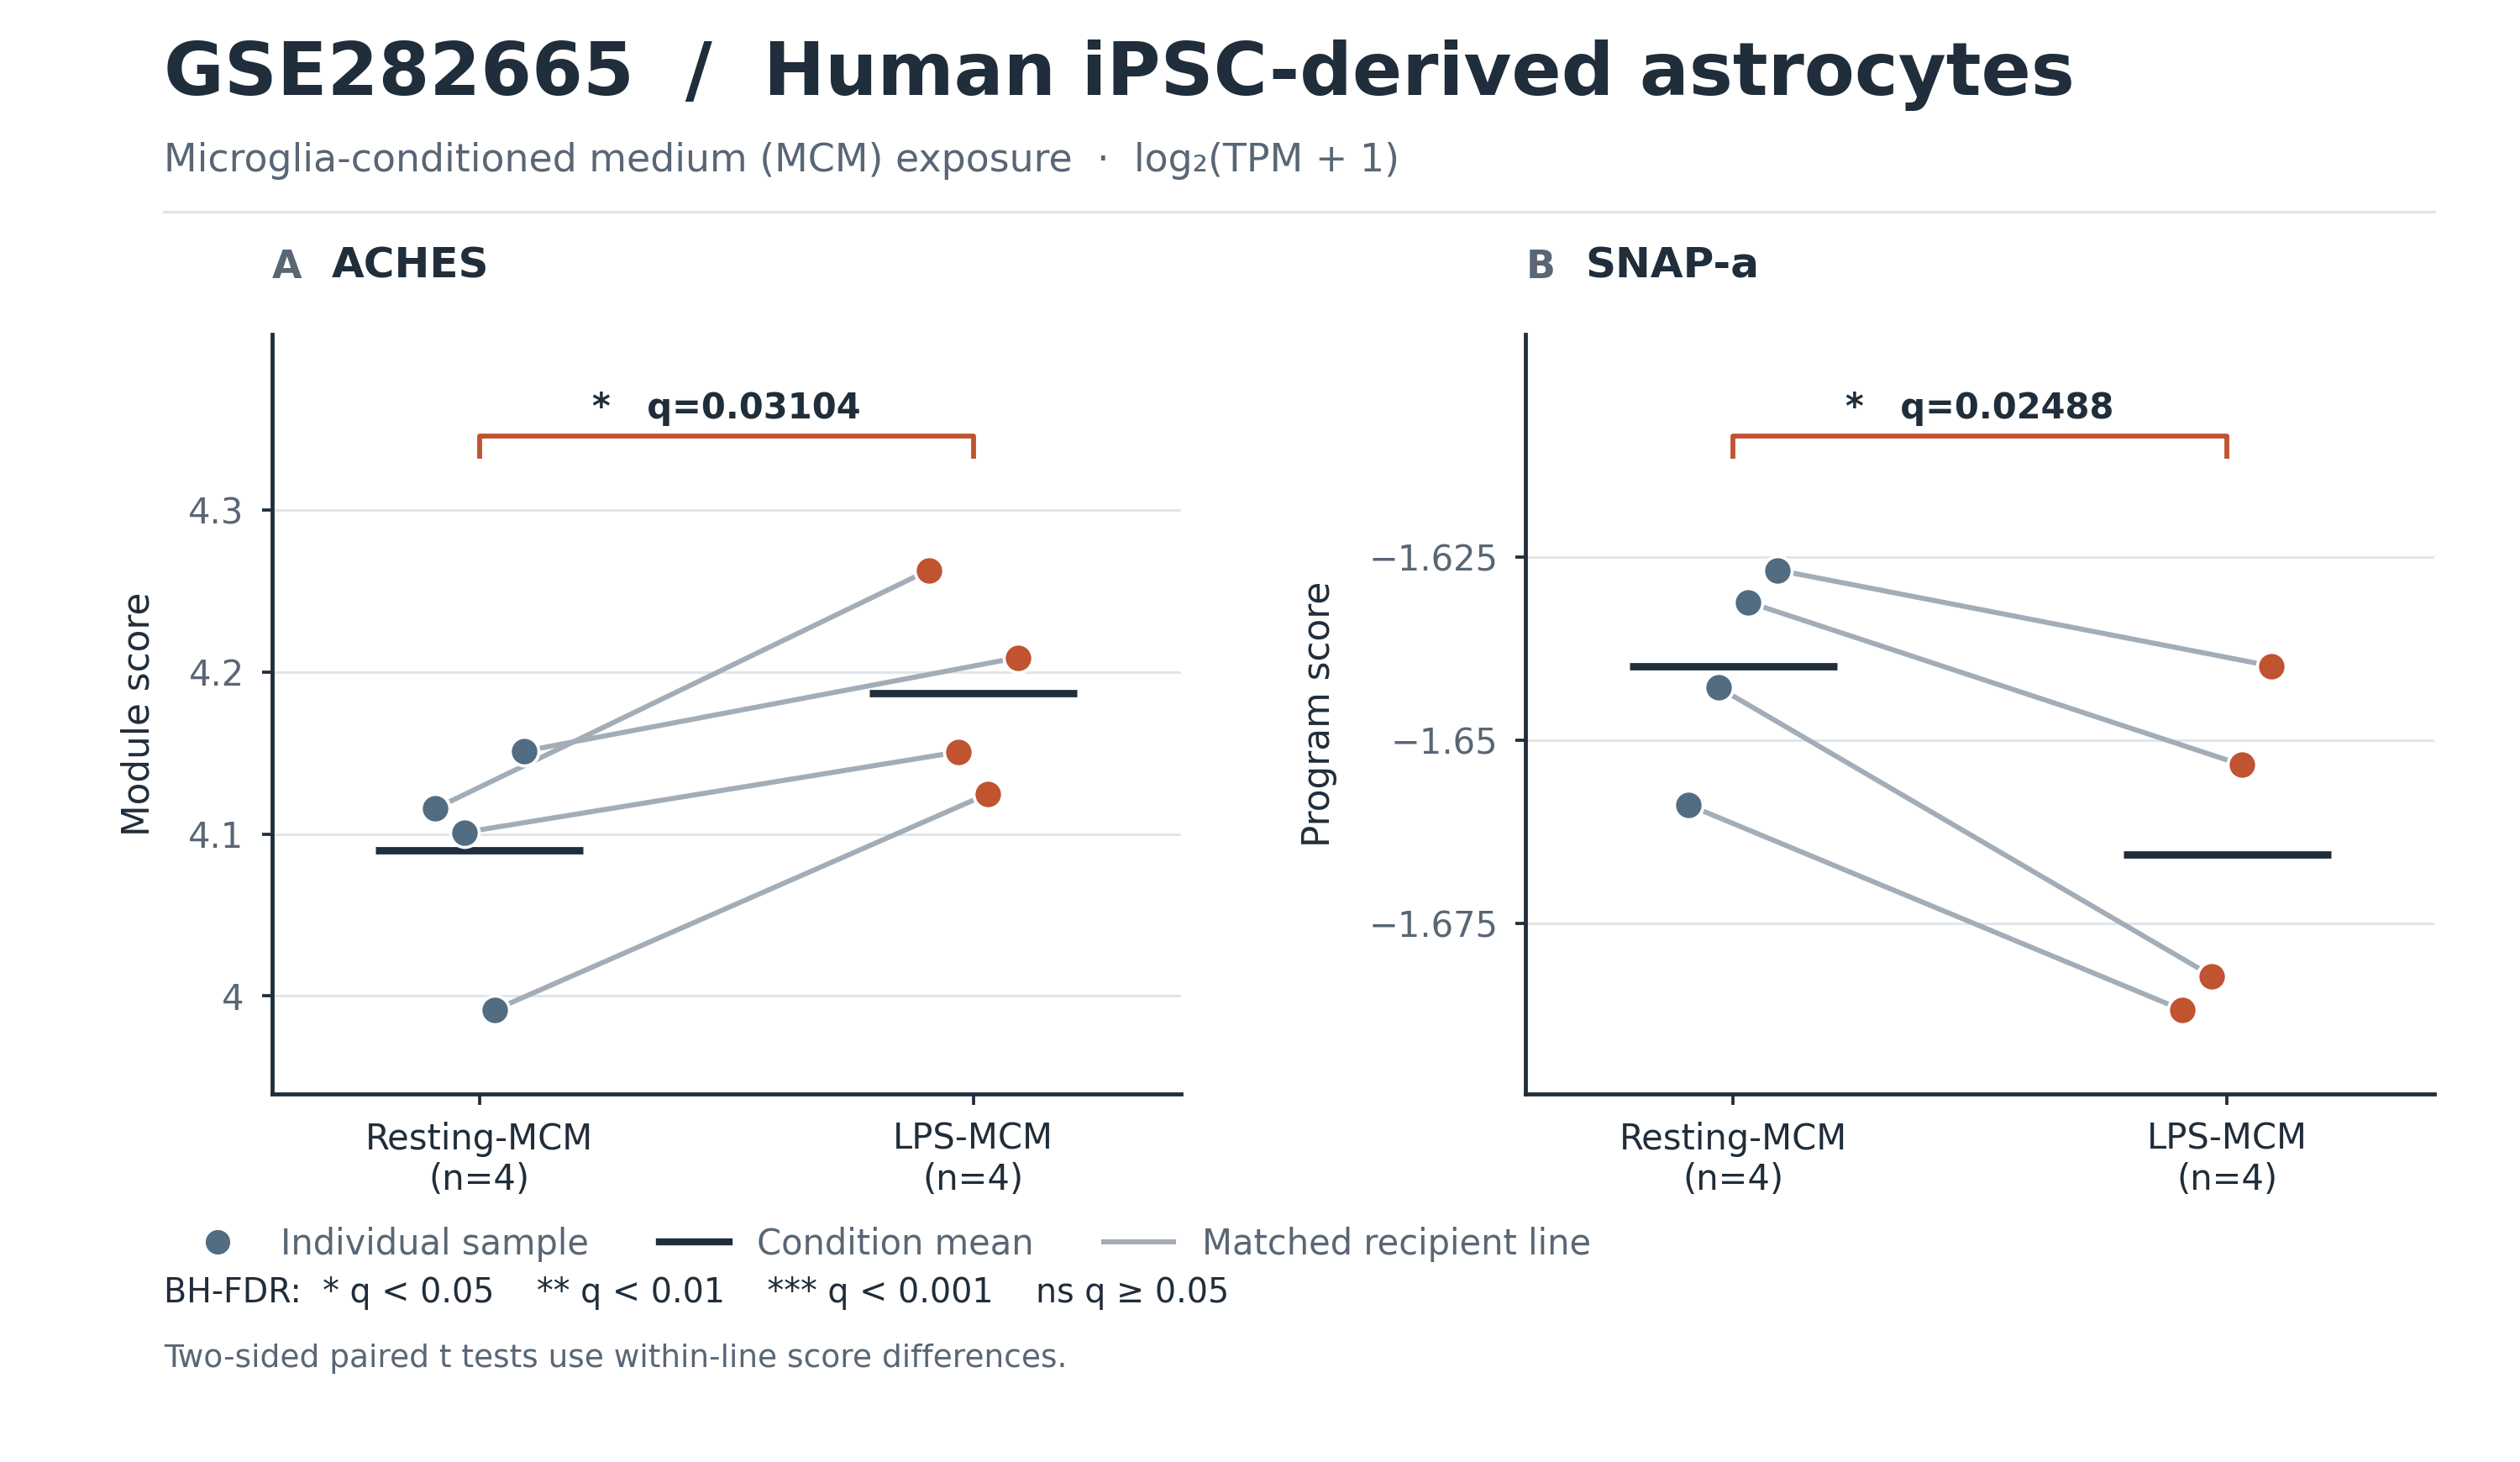

,dataset,recipient,program,treatment,method,n_reference,n_treatment,n_pairs,effect,ci_low,ci_high,p_value,q_value
0,GSE228927,astrocyte,ACHES,LPS-MCM,Welch t,3,3,NaN,0.45096,0.41195,0.48997,2.445e-05,9.782e-05
1,GSE228927,astrocyte,ACHES,Hemin-MCM,Welch t,3,3,NaN,0.44402,0.40355,0.48448,3.336e-05,0.0001001
2,GSE228927,astrocyte,SNAP-a,LPS-MCM,Welch t,3,3,NaN,-0.06897,-0.08725,-0.05069,0.001224,0.002448
3,GSE228927,astrocyte,SNAP-a,Hemin-MCM,Welch t,3,3,NaN,-0.08298,-0.09947,-0.06648,0.0004154,0.000623
4,GSE282665,astrocyte,ACHES,LPS-MCM,paired t,4,4,4.0,0.09702,0.01672,0.17732,0.03104,0.03104
5,GSE282665,astrocyte,SNAP-a,LPS-MCM,paired t,4,4,4.0,-0.02568,-0.04323,-0.00814,0.01866,0.02488


,dataset,recipient,program,scale,source_genes,retained_genes,gene_coverage,weight_mass_coverage,low_coverage
2,GSE228927,astrocyte,ACHES,log2(FPKM+1),363,305,0.840,0.840,False
3,GSE228927,astrocyte,SNAP-a,log2(FPKM+1),33611,13925,0.414,0.629,True
4,GSE282665,astrocyte,ACHES,log2(TPM+1),363,359,0.989,0.989,False
5,GSE282665,astrocyte,SNAP-a,log2(TPM+1),33611,25618,0.762,0.878,False


In [2]:
for number in figure_numbers.values():
    display(Image(filename=str(figures / f"{number}.png"), width=900))

effects = pd.read_csv(results / "program_score_effects_ci.tsv", sep="\t")
effects = effects.loc[effects["dataset"].isin(selected_datasets) & effects["recipient"].eq("astrocyte")]
effect_fields = ["dataset", "recipient", "program", "treatment", "method", "n_reference",
                 "n_treatment", "n_pairs", "effect", "ci_low", "ci_high", "p_value", "q_value"]
report = effects[effect_fields].copy()
for column in ("p_value", "q_value"):
    report[column] = report[column].map(lambda value: f"{value:.4g}")
display(report.round(5))
report_fields = ["dataset", "recipient", "program", "scale", "source_genes",
                 "retained_genes", "gene_coverage", "weight_mass_coverage", "low_coverage"]
display(coverage[report_fields].round(3))

## Astrocyte · ACHES와 SNAP-a

GSE228927에서는 resting-MCM(원본 `NOT`), LPS-MCM, hemin-MCM을 비교한다. GSE282665에서는 healthy-control astrocyte에 healthy-control microglia MCM을 처리한 표본을 사용한다. 발현량 단위와 채택한 유전자가 데이터셋별로 다르므로 점수는 각 패널 안에서 해석한다.

In [3]:
sample_fields = ["condition", "sample_id", "gsm_id", "ACHES", "SNAP-a"]
for dataset, frame in planned.groupby("dataset", sort=False):
    print(dataset)
    display(frame[sample_fields].reset_index(drop=True).round(6))

GSE228927
GSE282665


,condition,sample_id,gsm_id,ACHES,SNAP-a
0,Hemin-MCM,Hemin1,GSM7142967,3.424558,-1.445241
1,Hemin-MCM,Hemin2,GSM7142968,3.460659,-1.460679
2,Hemin-MCM,Hemin3,GSM7142969,3.456537,-1.456917
3,LPS-MCM,LPS1,GSM7142964,3.439877,-1.442374
4,LPS-MCM,LPS2,GSM7142965,3.475854,-1.447872
5,LPS-MCM,LPS3,GSM7142966,3.446845,-1.430563
6,Resting-MCM,NOT1,GSM7142961,3.012261,-1.376604
7,Resting-MCM,NOT2,GSM7142962,3.007125,-1.368154
8,Resting-MCM,NOT3,GSM7142963,2.990317,-1.369150


,condition,sample_id,gsm_id,ACHES,SNAP-a
0,LPS-MCM,ctrl1_ctrl_lps,GSM8669349,4.262867,-1.686818
1,LPS-MCM,ctrl2_ctrl_lps,GSM8669332,4.150663,-1.682190
2,LPS-MCM,ctrl4_ctrl_lps,GSM8669338,4.124825,-1.653338
3,LPS-MCM,ctrl6_ctrl_lps,GSM8669345,4.208856,-1.639849
4,Resting-MCM,ctrl1_ctrl_untx,GSM8669342,4.115617,-1.658843
5,Resting-MCM,ctrl2_ctrl_untx,GSM8669353,4.101048,-1.642758
6,Resting-MCM,ctrl4_ctrl_untx,GSM8669336,3.991370,-1.631112
7,Resting-MCM,ctrl6_ctrl_untx,GSM8669343,4.151096,-1.626751


[전체 표본 점수 TSV](../../data/perturbation_validation/results/planned_sample_scores.tsv) · [전체 대비 통계 TSV](../../data/perturbation_validation/results/program_score_effects_ci.tsv)

[GSE228927 그림 24 PDF](../../figures/24.pdf) · [SVG](../../figures/24.svg) · [GSE282665 그림 25 PDF](../../figures/25.pdf) · [SVG](../../figures/25.svg) · [전체 그림 색인](../../FIGURES.md)